# Renewable capacity vs. cost — diagnosing the "more renewables = cheaper, even at 700 GW" pattern (with-hydrogen model)

This notebook sweeps `renewable_capacity` from 200–800 GW (well past the CB7-scale range of ~150–350 GW normally explored) using `src.power_system.PowerSystem` (the with-hydrogen model), holding storage/DAC/gas capacity fixed, and compares two ways of computing £/MWh:

1. **Simulated cost** — `PowerSystem.calculate_energy_cost(sim)`: runs the full hourly/daily dispatch simulation (curtailment, storage, gas backup all resolved), then divides total system cost by the **fixed** UK 2050 demand (`A.EnergyDemand2050`, 692 TWh) — i.e. cost per MWh actually needed to serve.
2. **Naive average cost** — `total_system_cost(...) / (capacity × capacity_factor × hours)`: divides by the *nameplate average generation implied by capacity factor*, not by what's actually served. No simulation, no curtailment accounting.

If your own analysis is showing costs falling indefinitely as renewable capacity grows (even out to ~700 GW), it's almost certainly using something structurally like #2.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Make `src` importable whether the notebook is run from the repo root or from `nbs/`.
_root = Path.cwd().resolve()
while _root != _root.parent and not (_root / "src").exists():
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))
OUTPUT_DIR = _root / "nbs" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import src.assumptions as A
import src.matplotlib_style  # noqa: F401
from src.costs import total_system_cost
from src.data import renewable_capacity_factors
from src.demand_model import DemandMode, predicted_demand
from src.power_system import PowerSystem
from src.supply_model import daily_renewables_capacity
from src.units import Units as U

In [2]:
DEMAND_MODE = DemandMode.SEASONAL
CAPACITY_FACTORS_SOURCE = "era5_2024"
ENABLE_IMPORTS = False
DAC_GW = 2

# Fixed storage/backup sizing across the whole sweep, so only renewable_capacity varies.
HYDROGEN_STORAGE_TWH = A.HydrogenStorage.CavernStorage.Capacity
ELECTROLYSER_GW = A.HydrogenStorage.Electrolysis.Power
HYDROGEN_GEN_GW = A.HydrogenStorage.Generation.Power

REN_GW_LIST = [200, 250, 300, 350, 400, 500, 600, 700, 800]

demand_df = predicted_demand(mode=DEMAND_MODE, historical="era5", filter_ldz=True)
daily_cf = renewable_capacity_factors.get_renewable_capacity_factors(source=CAPACITY_FACTORS_SOURCE, resample="D")


def build_net_supply_df(ren_gw: int) -> pd.DataFrame:
    supply = daily_renewables_capacity(ren_gw * U.GW, daily_cf)
    common_idx = supply.index.intersection(demand_df.index)
    supply = supply.reindex(common_idx)
    demand = demand_df.reindex(common_idx)
    net_supply_df = (supply - demand["demand"]).to_frame(name=f"S-D(TWh),Ren={ren_gw}GW")
    return net_supply_df.reset_index().rename(columns={net_supply_df.reset_index().columns[0]: "index"})

## 1. Simulated cost (correct: accounts for curtailment, divides by fixed served demand)

In [3]:
rows = []
for ren_gw in REN_GW_LIST:
    net_supply_df = build_net_supply_df(ren_gw)
    ps = PowerSystem(
        renewable_capacity=ren_gw * U.GW,
        hydrogen_storage_capacity=HYDROGEN_STORAGE_TWH,
        electrolyser_power=ELECTROLYSER_GW,
        dac_capacity=DAC_GW * U.GW,
        hydrogen_generation_power=HYDROGEN_GEN_GW,
        enable_imports=ENABLE_IMPORTS,
        capacity_factors_source=CAPACITY_FACTORS_SOURCE,
        enable_gas_ltdac=True,
    )
    sim = ps.run_simulation(net_supply_df)
    if sim is None:
        rows.append({"ren_gw": ren_gw, "status": "failed (storage depleted)"})
        continue
    analysis = ps.analyze_simulation_results(sim)
    rows.append({
        "ren_gw": ren_gw,
        "status": "ok",
        "simulated_cost_GBP_per_MWh": ps.calculate_energy_cost(sim).to(U.GBP / U.MWh).magnitude,
        "curtailed_TWh": analysis["curtailed_energy"].to(U.TWh).magnitude,
        "gas_ccs_TWh": analysis["annual_gas_ccs_energy"].to(U.TWh).magnitude,
    })

sim_results = pd.DataFrame(rows)
sim_results

,ren_gw,status,simulated_cost_GBP_per_MWh,curtailed_TWh,gas_ccs_TWh
0,200,ok,74.555141,60.588867,31.332253
1,250,ok,82.050368,214.526049,13.196829
2,300,ok,91.303740,375.105691,5.908074
3,350,ok,101.451290,537.929983,2.817825
4,400,ok,112.063927,701.546902,1.338908
5,500,ok,133.899745,1030.032092,0.368883
6,600,ok,156.060684,1358.956915,0.154782
7,700,ok,178.316163,1687.921964,0.077682
8,800,ok,200.601333,2016.868885,0.032896


## 2. Naive average cost (no simulation: divides by nameplate capacity × capacity factor × hours, not by served demand)

In [4]:
naive_rows = []
for ren_gw in REN_GW_LIST + [900, 1200]:
    base_cost = total_system_cost(
        energy_demand=A.EnergyDemand2050,
        renewable_capacity=ren_gw * U.GW,
        renewable_capacity_factor=A.Renewables.AverageCapacityFactor,
        renewable_lcoe=A.Renewables.AverageLCOE,
        nuclear_capacity=A.Nuclear.Capacity,
        nuclear_capacity_factor=A.Nuclear.CapacityFactor,
        nuclear_lcoe=A.Nuclear.AverageLCOE,
        storage_capacity=HYDROGEN_STORAGE_TWH,
        electrolyser_power=ELECTROLYSER_GW,
        generation_capacity=HYDROGEN_GEN_GW,
    )
    nameplate_generation = (
        ren_gw * U.GW * A.Renewables.AverageCapacityFactor * A.HoursPerYear
        + A.Nuclear.Capacity * A.Nuclear.CapacityFactor * A.HoursPerYear
    )
    naive_rows.append({
        "ren_gw": ren_gw,
        "naive_cost_GBP_per_MWh": (base_cost / nameplate_generation).to(U.GBP / U.MWh).magnitude,
    })

naive_results = pd.DataFrame(naive_rows)
naive_results

,ren_gw,naive_cost_GBP_per_MWh
0,200,84.068707
1,250,81.286696
2,300,79.319047
3,350,77.853838
4,400,76.720411
5,500,75.081357
6,600,73.953215
7,700,73.129311
8,800,72.501197
9,900,72.006495


C:\Users\Yutong Ren\AppData\Local\Temp\ipykernel_37472\1172380843.py:16: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


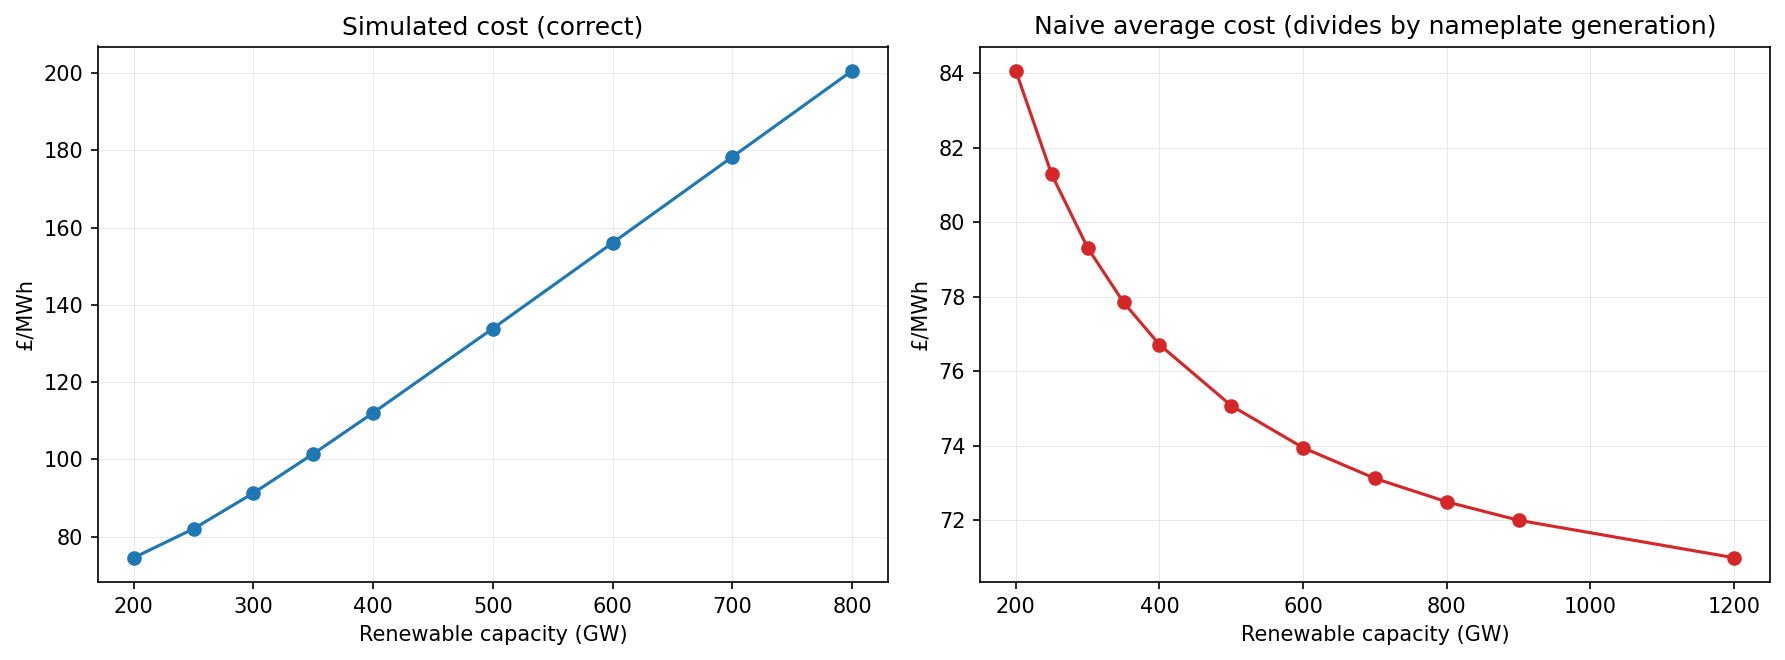

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ok = sim_results[sim_results["status"] == "ok"]
axes[0].plot(ok["ren_gw"], ok["simulated_cost_GBP_per_MWh"], marker="o")
axes[0].set_title("Simulated cost (correct)")
axes[0].set_xlabel("Renewable capacity (GW)")
axes[0].set_ylabel("£/MWh")
axes[0].grid(True, alpha=0.3)

axes[1].plot(naive_results["ren_gw"], naive_results["naive_cost_GBP_per_MWh"], marker="o", color="tab:red")
axes[1].set_title("Naive average cost (divides by nameplate generation)")
axes[1].set_xlabel("Renewable capacity (GW)")
axes[1].set_ylabel("£/MWh")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "renewable_vs_cost_check.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

- **Simulated cost rises** with renewable capacity (~£75/MWh at 200 GW → ~£200/MWh at 800 GW), because curtailment explodes: at 800 GW, ~2,000 TWh/yr is curtailed against only 692 TWh/yr of demand — i.e. the system is paying to build ~3x more renewable capacity than it can ever use, and that capex isn't offset by anything.
- **Naive average cost falls** monotonically and flattens near ~£70–£75/MWh even at 700–1200 GW, because it divides total cost by *nameplate average generation* (`capacity × capacity_factor × hours`) instead of by demand actually served. Fixed costs (nuclear, storage capex, `AdditionalCosts`) get diluted over an ever-larger phantom denominator that includes energy nobody uses. This is a pure denominator artifact, not a real economy of scale.

If your model shows cost falling as renewable capacity → 700 GW+, check whether its cost-per-MWh divides by `capacity × capacity_factor × hours` (or similar) rather than by the fixed served energy demand / a curtailment-aware simulated delivered-energy figure.